# Ignition: Chicken-and-Egg, Lock-In, and Tipping

> Computational Analysis of Social Complexity
>
> Fall 2026, Spencer Lyon

**Prerequisites**

- [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb)
- {term}`Game theory <game theory>` (week 8)
- {term}`ABM <agent-based model (ABM)>` concepts (week 6)
- {term}`Graphs <graph>` (week 3)

**Outcomes**

- Model the {term}`chicken-and-egg problem` as a coordination game with multiple equilibria
- Simulate increasing-returns adoption and explain {term}`lock-in` and {term}`path dependence`
- Analyze {term}`threshold adoption <threshold adoption rule>` on networks and identify {term}`tipping` conditions
- Evaluate when {term}`winner-take-all` does and does not apply

**References**

- [Easley & Kleinberg, Chapter 19: Cascading Behavior in Networks](https://www.cs.cornell.edu/home/kleinber/networks-book/networks-book.pdf) (required)
- Arthur (1989), *Competing Technologies, {term}`Increasing Returns <increasing returns>`, and Lock-In by Historical Events*
- *Matchmakers* (Evans & Schmalensee, 2016), Chapter 5 (optional extra reading)

In [1]:
using GameTheory
using Graphs
using Plots
using Random
using Statistics

## Two Platforms Walk into a Market

- OpenTable launched in 1998 with a problem
  - Diners would not visit a reservation {term}`platform` with no restaurants
  - Restaurants would not buy into a platform with no diners
- Its response was intensely local
  - Install reservation terminals in San Francisco restaurants
  - Make the service free for diners
  - Build enough density in one city, then repeat
- OpenTable ignited

### A Second Story

- Windows Phone launched in 2010
- Microsoft spent billions and reviewers praised much of the hardware
- But users asked: where are the apps?
- Developers asked: where are the users?
- No apps $\rightarrow$ no users $\rightarrow$ no apps
- By 2017, the platform was effectively dead

### The Tension

- Same **chicken-and-egg problem**
- Opposite outcomes
- Recall from [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb):
  - **{term}`Same-side network effects <same-side network effect>`** connect participants on one side
  - **{term}`Cross-side network effects <cross-side network effect>`** connect activity across sides
- What separates ignite from fizzle?
- Today we study three answers: {term}`equilibrium selection`, increasing returns, and network structure

## Build 1: Chicken-and-Egg as a Game

- Let the two players be Restaurants and Diners
- Each chooses one action: `Join` or `Stay out`
- Joining together creates value for both sides
- Joining alone is costly
- Staying out is safe, but produces no platform value
- Before calculating anything: what outcomes seem self-reinforcing?

### Payoffs

- Rows are the Restaurant's action: `Join`, then `Stay out`
- Columns are the Diner's action: `Join`, then `Stay out`
- Each cell reports `(Restaurant, Diner)`

$$
\begin{array}{c|cc}
 & \text{Diner: Join} & \text{Diner: Stay\ out} \\
\hline
\text{Restaurant: Join} & (3,3) & (-2,0) \\
\text{Restaurant: Stay\ out} & (0,-2) & (0,0)
\end{array}
$$

- The numbers are illustrative; their ordering carries the economics

In [2]:
restaurant_payoffs = [3 -2; 0 0]
diner_payoffs = [3 -2; 0 0]

restaurant = Player(restaurant_payoffs)
diner = Player(diner_payoffs)
platform_game = NormalFormGame([restaurant, diner])

2×2 NormalFormGame{2, Int64}:
 (3, 3)   (-2, 0)
 (0, -2)  (0, 0)

### Recall from Week 8: Use Best Responses

- If Diners join, the Restaurant's {term}`best response` is to join: $3 > 0$
- If Diners stay out, the Restaurant's best response is to stay out: $0 > -2$
- The Diner faces the same logic
- A {term}`Nash equilibrium` is an action profile in which both actions are best responses
- Question: can there be more than one?

In [3]:
coordination_equilibria = pure_nash(platform_game)

[(actions = eq, payoffs = platform_game[eq...]) for eq in coordination_equilibria]

2-element Vector{@NamedTuple{actions::Tuple{Int64, Int64}, payoffs::Vector{Int64}}}:
 (actions = (1, 1), payoffs = [3, 3])
 (actions = (2, 2), payoffs = [0, 0])

### The Bad Outcome Is Also an Equilibrium

- `(Join, Join)` is a Nash equilibrium
- `(Stay out, Stay out)` is also a Nash equilibrium
- [this figure](#fig-ignition-two-equilibria) marks both equilibria and the best-response arrows that sustain each one
- At the bad equilibrium, neither side wants to join alone
- The good equilibrium is Pareto-superior, but that does not make beliefs coordinate on it
- A platform's first job is therefore **equilibrium selection**
- **{term}`Critical mass <critical mass>`** is the participation level beyond which joining becomes self-sustaining

<a name="fig-ignition-two-equilibria" href="#fig-ignition-two-equilibria" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Best responses for both Restaurant and Diner converge on two self-reinforcing outcomes: (Join, Join), which is Pareto-superior, and (Stay out, Stay out), which is inefficient but self-sustaining because neither side wants to join alone.

### Divide and Conquer

- Suppose the platform subsidizes Restaurants
- A terminal, onboarding help, or guaranteed revenue makes joining worthwhile even before Diners arrive
- Change the Restaurant payoff from joining alone from $-2$ to $1$
- `Join` is now a {term}`dominant strategy` for Restaurants
- Once Restaurants join, Diners' best response is to join
- This is about **{term}`price structure`**, not merely the total **{term}`price level`** charged across both sides

In [4]:
subsidized_restaurant_payoffs = [3 1; 0 0]
subsidized_game = NormalFormGame([
    Player(subsidized_restaurant_payoffs),
    Player(diner_payoffs),
])

subsidized_equilibria = pure_nash(subsidized_game)
[(actions = eq, payoffs = subsidized_game[eq...]) for eq in subsidized_equilibria]

1-element Vector{@NamedTuple{actions::Tuple{Int64, Int64}, payoffs::Vector{Int64}}}:
 (actions = (1, 1), payoffs = [3, 3])

### The Platform Changed the Game

- The subsidy did more than make joining slightly nicer
- Which equilibrium survives once Restaurants have a dominant strategy to join? [this figure](#fig-subsidy-deletes-equilibrium) compares the game before and after the subsidy
- It deleted the `(Stay out, Stay out)` equilibrium
- OpenTable's city-by-city strategy concentrated the subsidy where cross-side network effects could become dense
- Ignition is not just attracting users
- Ignition is moving expectations across a coordination threshold

<a name="fig-subsidy-deletes-equilibrium" href="#fig-subsidy-deletes-equilibrium" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Raising the Restaurant's join-alone payoff from -2 to 1 makes Join a dominant strategy for Restaurants, so Diners' best response becomes Join too; (Stay out, Stay out) stops being a Nash equilibrium and only (Join, Join) survives.

### Exercise 1: Coordination without Coordination

- Why does `(Join, Join)` being Pareto-superior not guarantee that it is played?
- Describe the belief each side can hold at `(Stay out, Stay out)`
- Name a real platform that may have become stuck near this bad equilibrium
- What observable commitment could change one side's best response?

## Build 2: The Race to Critical Mass

- Now suppose two platforms already have a few adopters
- Platforms A and B have identical quality
- Each period, one new adopter arrives
- More previous adopters make a platform more attractive
- This is Arthur's increasing-returns logic in an urn-like model
- Can tiny early accidents decide a large market?

### Start with an Urn

- Picture an urn holding one blue ball (platform A) and one orange ball (platform B)
- Each new adopter reaches in, draws a ball at random, and joins that ball's platform
- Then they put the ball back **and add one more of the same color**
- A platform that gets lucky early now has more balls in the urn, so it is more likely to be drawn again
- This is a **Pólya urn**. Arthur's increasing-returns adoption model (1989) behaves like a generalized version of it
- Press Play and let several urns finish. Do they all end at the same share of blue?
- Then switch to $\gamma=2$, where each draw is tilted toward whichever color already leads
- The animation runs on the course website; in Jupyter, the simulation below tells the same story

```{anywidget} ./polya_urn.mjs
{
  "gamma": 1,
  "max_draws": 200
}
```

### A Reinforced Adoption Rule

- Let $n_A(t)$ and $n_B(t)$ be installed bases at time $t$
- The next adopter chooses A with probability

$$
P(A \mid t) = \frac{n_A(t)^\gamma}{n_A(t)^\gamma + n_B(t)^\gamma}.
$$

- At $\gamma=1$, this is the classic linear Pólya urn
- At $\gamma>1$, network value grows more than proportionally with installed base
- We use $\gamma=2$: identical quality, but strong increasing returns

In [5]:
function reinforced_adoption(T; nA0 = 1, nB0 = 1, gamma = 2.0)
    nA = nA0
    nB = nB0
    shareA = Vector{Float64}(undef, T + 1)
    shareA[1] = nA / (nA + nB)

    for t in 1:T
        weightA = nA^gamma
        weightB = nB^gamma
        if rand() < weightA / (weightA + weightB)
            nA += 1
        else
            nB += 1
        end
        shareA[t + 1] = nA / (nA + nB)
    end

    return shareA
end

reinforced_adoption (generic function with 1 method)

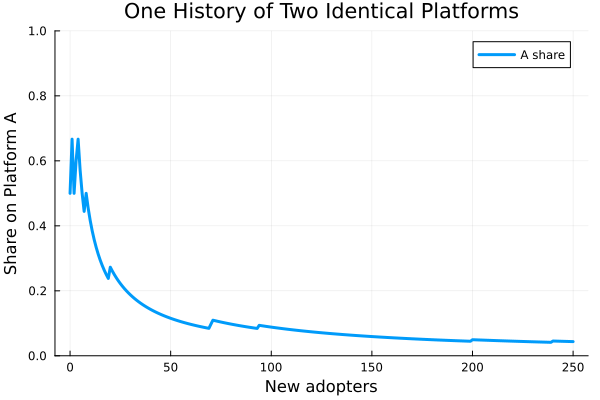

In [6]:
Random.seed!(6318)
T = 250
one_path = reinforced_adoption(T)

plot(
    0:T, one_path;
    xlabel = "New adopters",
    ylabel = "Share on Platform A",
    ylim = (0, 1),
    linewidth = 3,
    label = "A share",
    title = "One History of Two Identical Platforms",
)

### One History Is Not a Result

- That curve feels like a story about Platform A
- But A and B have exactly the same quality
- Change the random seed and the story may reverse
- Recall from week 6: an ABM describes a distribution over outcomes
- Let us run 200 possible histories

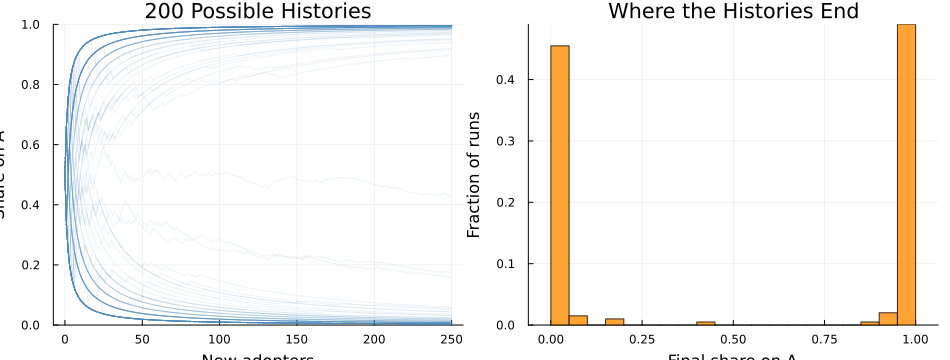

In [7]:
Random.seed!(631802)
n_runs = 200
paths = reduce(hcat, [reinforced_adoption(T) for _ in 1:n_runs])
final_shares = paths[end, :]

trajectory_plot = plot(
    0:T, paths;
    color = :steelblue, alpha = 0.10, label = false,
    xlabel = "New adopters", ylabel = "Share on A", ylim = (0, 1),
    title = "200 Possible Histories",
)
final_plot = histogram(
    final_shares;
    bins = 0:0.05:1, normalize = :probability,
    color = :darkorange, alpha = 0.8, label = false,
    xlabel = "Final share on A", ylabel = "Fraction of runs",
    title = "Where the Histories End",
)

plot(trajectory_plot, final_plot; layout = (1, 2), size = (950, 360))

In [8]:
lock_in_rate = mean((final_shares .<= 0.10) .| (final_shares .>= 0.90))
(lock_in_rate = lock_in_rate, A_wins = mean(final_shares .> 0.5))

(lock_in_rate = 0.98, A_wins = 0.515)

## Lock-In without a Quality Difference

- Nearly every strongly reinforced run ends near 0 or 1
- This is **tipping**: positive feedback pushes the market toward one dominant platform
- But which platform wins is early random luck, not quality
- That sensitivity to history is **path dependence**
- Lock-in means later adopters rationally follow a lead created by earlier accidents
- Important qualification: the linear case $\gamma=1$ is path dependent, but its final shares need not be winner-take-all
- Winner-take-all is a result to explain, not a slogan to assume

### Emergence, Again

- As with segregation in week 6, a stark aggregate outcome {term}`emerges <emergence>` that no individual chose
- Each adopter makes a locally sensible choice
- Collectively, those choices can make one platform almost unavoidable
- Sidecar entered ride-hailing early, but Uber's growing driver-rider network helped pull later adoption toward Uber
- The model does not claim quality never matters
- It shows why timing and early scale can matter even when quality is equal

### Critical Mass on Two Sides

- Could many diners rescue a platform with few restaurants?
- Our race tracked one market share. Now $n_A,n_B$ are participation fractions on **two sides of one platform**
- Evans & Schmalensee (*Matchmakers*, ch. 5) describe a **{term}`critical mass frontier`**: a curve, not one number
- Northeast lies the growth zone; southwest, the implosion zone. Starting at $(0,0)$, we must cross it
- As in [Platforms and Matchmakers](../week10/L10.01_platform_economics.ipynb), current adoption anchors expectations. Here each side moves halfway toward an S-shaped response to the other side

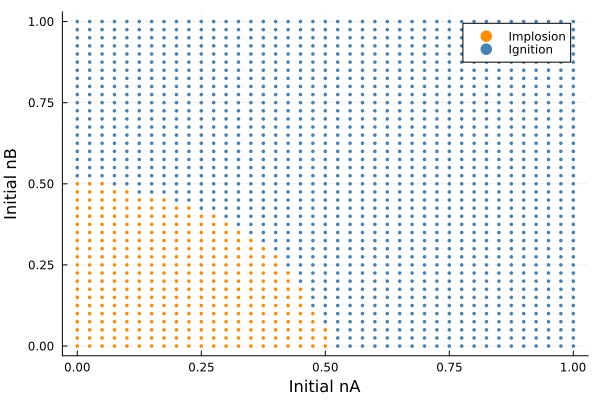

In [ ]:
response(n) = 1 / (1 + exp(-12 * (n - 0.4)))
function ignites(nA, nB)
    for _ in 1:200
        nA, nB = (nA + response(nB)) / 2, (nB + response(nA)) / 2
    end
    return nA + nB > 1
end

starts = [(a, b) for a in 0:0.025:1 for b in 0:0.025:1]
p = plot(; xlabel = "Initial nA", ylabel = "Initial nB", legend = :topright)
for (outcome, color, label) in [(false, :darkorange, "Implosion"), (true, :steelblue, "Ignition")]
    points = filter(s -> ignites(s...) == outcome, starts)
    scatter!(p, first.(points), last.(points); color, label, markersize = 2, markerstrokewidth = 0)
end
p

- The color boundary approximates the frontier; implosion here means near-zero participation. Parameters are illustrative
- How does a platform get from $(0,0)$ across the frontier? *Matchmakers* (ch. 5) names three **ignition strategies**:
  - **Zigzag (YouTube)**: push both coordinates up in turn
  - **Two-step (OpenTable)**: build and hold one side first, then move along the other axis
  - **Commitment (Xbox)**: promised low console prices raise expected users, moving developer participation up
- [this figure](#fig-ignition-strategies-paths) traces the three strategies as routes across the frontier
- Platforms also use **tactics** to make the trip shorter:
  - **Self-supply** adds to one coordinate
  - **Marquee participants** make that side more attractive, pulling the frontier inward
  - **Shaping expectations** moves the perceived starting point; actual participation must follow

<a name="fig-ignition-strategies-paths" href="#fig-ignition-strategies-paths" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Zigzag, two-step, and commitment trace different routes across the critical mass frontier in the participation plane; marquee participants and self-supply pull the frontier inward, shrinking the implosion zone.

### Exercise 2: What Breaks Lock-In?

- Our adoption rule has one force: installed base. Real adopters also care about **quality**, and many join **more than one platform**
- We add each force to the model, one at a time, and ask whether lock-in survives

**Part A: Quality**

- Give platform A a quality multiplier $\theta \geq 1$:

$$
P(A \mid t) = \frac{\theta\, n_A(t)^\gamma}{\theta\, n_A(t)^\gamma + n_B(t)^\gamma}.
$$

- $\theta$ stands in for everything an adopter values apart from who else is there: features, price, reliability
- At equal installed bases, $\theta = 1.2$ means A wins about 55% of new adopters instead of 50%
- Now let B start with a head start: $n_A(0)=1$, $n_B(0)=5$, and $\gamma=2$
- Before computing: on the very first draw, how large must $\theta$ be for A to be favored? (Compare $\theta \cdot 1^2$ with $5^2$)
- Then simulate: how large must $\theta$ be before A wins most runs? What does this say about a better product that arrives late?

**Part B: Multihoming**

- So far every adopter picks exactly one platform
- Suppose each adopter **multihomes** with probability $m$: they join both, so $n_A$ and $n_B$ each grow by one
- With probability $1-m$ they single-home, using the reinforced rule above
- Multihomers add the same amount to both platforms, so they dilute any lead that {term}`single-homers <single-homing>` build
- Simulate $\gamma=2$ with $m \in \{0, 0.25, 0.5\}$ and plot a histogram of final shares for each
- Derive the largest share the leader can ever reach when A wins *every* single-homer. (Hint: per period, A gains about 1 adopter and B gains about $m$)
- Why do riders who install both Uber and Lyft keep ride-hailing from becoming winner-take-all?

**Part C: Weaker returns**

- Predict what happens to the spread of final shares as $\gamma$ falls below 1, then check with `reinforced_adoption`

In [ ]:
function adoption_with_frictions(T; nA0 = 1, nB0 = 1, gamma = 2.0, theta = 1.0, m = 0.0)
    nA, nB = nA0, nB0
    for t in 1:T
        # TODO: with probability m, the adopter multihomes: add one to both nA and nB
        # TODO: otherwise choose A with probability theta * nA^gamma / (theta * nA^gamma + nB^gamma)
    end
    return nA / (nA + nB)
end

# Part A
# TODO: for theta in [1, 5, 25, 50], run 200 simulations with nB0 = 5
# TODO: report the fraction of runs in which A ends with more than half the market

# Part B
# TODO: for m in [0, 0.25, 0.5], run 200 simulations and plot a histogram of final shares
nothing

## Build 3: Networks Matter

- The urn treats every adopter as if they observe the whole market
- Real adoption often arrives through neighbors
- Recall cascades from our graph lectures
- An agent adopts when enough of their neighbors have adopted
- Does critical mass depend only on the number of seeds?

In [9]:
Random.seed!(1202)
n = 120
g_er = erdos_renyi(n, 0.05)
g_ws = watts_strogatz(n, 6, 0.08)

(
    erdos_renyi = (edges = ne(g_er), mean_degree = mean(degree(g_er))),
    watts_strogatz = (edges = ne(g_ws), mean_degree = mean(degree(g_ws))),
)

(erdos_renyi = (edges = 335, mean_degree = 5.583333333333333), watts_strogatz = (edges = 360, mean_degree = 6.0))

### A Threshold Rule

- Each {term}`node` is either adopted or not adopted
- Seeds adopt at time 0
- Everyone else adopts when at least a fraction $\tau$ of their neighbors has adopted

$$
a_i(t+1) = 1 \quad \text{if} \quad \frac{\sum_{j \in N(i)} a_j(t)}{|N(i)|} \ge \tau.
$$

- Updates are synchronous: everyone responds to the previous round
- Adoption is irreversible in this simple model
- On a small toy network with seeds $A$ and $B$ and $\tau=0.5$: which node adopts last, and why? [this figure](#fig-threshold-cascade) walks through four rounds of the cascade

<a name="fig-threshold-cascade" href="#fig-threshold-cascade" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Seeds A and B push the cascade through C, D, and F as each crosses the τ = 0.5 threshold, but the triangle G-H-I stalls forever: G sees only 1 of its 3 neighbors adopted, and H and I see none, so none of them ever reaches τ.

In [10]:
function threshold_adoption(g, seeds, tau; max_steps = 40)
    adopted = falses(nv(g))
    adopted[seeds] .= true
    adoption_rate = Float64[mean(adopted)]

    for _ in 1:max_steps
        next_adopted = copy(adopted)
        for v in vertices(g)
            if !adopted[v]
                nbrs = neighbors(g, v)
                if !isempty(nbrs) && mean(adopted[nbrs]) >= tau
                    next_adopted[v] = true
                end
            end
        end

        next_adopted == adopted && break
        adopted = next_adopted
        push!(adoption_rate, mean(adopted))
    end

    return adoption_rate
end

threshold_adoption (generic function with 1 method)

### Random or Targeted Seeding?

- We have a budget of five seeds
- Strategy 1: choose five nodes at random
- Strategy 2: target high-degree nodes
- On the Watts-Strogatz graph, we also keep targeted seeds locally concentrated
  - Local reinforcement matters when adoption uses a fractional threshold
- We compare the same seed budget and the same threshold across topologies

In [11]:
Random.seed!(12025)
random_seeds = sort(randperm(n)[1:5])
er_degrees = degree(g_er)
ws_degrees = degree(g_ws)
er_targeted = sort(partialsortperm(er_degrees, 1:5; rev = true))

# Choose the highest-degree block of five nearby nodes on the WS ring.
ws_windows = [[mod1(start + offset, n) for offset in 0:4] for start in 1:n]
ws_targeted = ws_windows[argmax([sum(ws_degrees[w]) for w in ws_windows])]

(random = random_seeds, er_targeted = er_targeted, ws_targeted = ws_targeted)

(random = [17, 31, 32, 100, 120], er_targeted = [7, 33, 72, 80, 93], ws_targeted = [75, 76, 77, 78, 79])

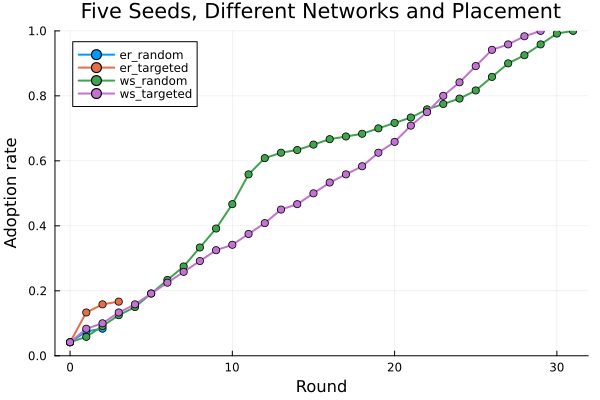

In [12]:
tau = 0.30
curves = (
    er_random = threshold_adoption(g_er, random_seeds, tau),
    er_targeted = threshold_adoption(g_er, er_targeted, tau),
    ws_random = threshold_adoption(g_ws, random_seeds, tau),
    ws_targeted = threshold_adoption(g_ws, ws_targeted, tau),
)

p = plot(; xlabel = "Round", ylabel = "Adoption rate", ylim = (0, 1),
    title = "Five Seeds, Different Networks and Placement")
for (label, curve) in pairs(curves)
    plot!(p, 0:(length(curve) - 1), curve; marker = :circle, linewidth = 2, label = string(label))
end
p

## Critical Mass Has a Shape

- Five seeds are not simply five seeds
- Their location determines how much local reinforcement they create
- Erdős-Rényi links scatter influence differently from clustered Watts-Strogatz links
- The same random seed identities can therefore produce different paths across the two graphs
- Targeting high-degree nodes expands reach; concentrating seeds can help neighbors cross a fractional threshold
- **Tipping** occurs when one round creates enough adopters to trigger the next
- Topology changes where critical mass lies

### A Warning about Influence

- High degree does not automatically mean easy to persuade
- A high-degree node may require many adopting neighbors to reach the same fractional threshold
- Seeding a hub can be powerful because many others observe it
- Waiting for a hub to adopt can be difficult because the hub observes many others
- Network interventions must distinguish outgoing reach from incoming social proof
- [this figure](#fig-hub-reach-vs-persuasion) contrasts the hub's outgoing reach with the adopting neighbors it needs incoming

<a name="fig-hub-reach-vs-persuasion" href="#fig-hub-reach-vs-persuasion" tabindex="-1" title="Notebook diagram anchor">&#8203;</a>

Outgoing edges show one adopting hub reaching ten neighbors at once; incoming edges show the same hub needing ⌈τ·10⌉ = 3 adopting neighbors before it adopts, versus a degree-2 node that needs only ⌈τ·2⌉ = 1. High degree amplifies reach, not persuadability.

## When Winner-Take-All Does Not Apply

- **{term}`Multihoming <multihoming>`** means participating on more than one platform
- Riders can install both Uber and Lyft
- Drivers can accept work from both
- Multihoming weakens the feedback that makes one platform exclusive
- Coexistence is more likely when switching is easy, differentiation matters, or {term}`network effects <network effect>` are local
- Strong network effects can create concentration without creating a single winner

### Craigslist and Local Network Effects

- Craigslist looks like one giant marketplace
- But a renter in Orlando gains little from apartment listings in Seattle
- A job seeker may care about one occupation and one city, not the whole site
- Competitors can unbundle a broad platform vertical by vertical
- The relevant network effect may live inside a category, geography, or community
- Before predicting winner-take-all, ask: *which network is actually reinforcing which choice?*

### Exercise 3: Give the Better Platform an Edge

- Let Platform A be 10% more attractive than B
- Set $\theta=1.1$ and choose A with probability proportional to $\theta n_A$ versus $n_B$
- Run 500 simulations
- How often does the better platform finish with less than half the market?
- Interpret a loss: does it prove that quality is irrelevant?

In [13]:
function better_platform_loss_rate(; theta = 1.1, runs = 500, T = 250)
    # TODO: repeat the adoption simulation `runs` times.
    # TODO: in each period use pA = theta * nA / (theta * nA + nB).
    # TODO: return the fraction of runs in which final nA < nB.
    return missing
end

# TODO: set a seed, call the function, and explain the result.
better_platform_loss_rate()

missing

### Exercise 4: Where Do Cascades Die?

- Use the Watts-Strogatz graph and the five targeted seeds
- Vary $\tau \in \{0.1, 0.3, 0.5\}$
- Plot all three adoption curves
- For which thresholds does the cascade reach most of the graph?
- Identify the first round in which each failed cascade stops growing

In [14]:
taus = [0.1, 0.3, 0.5]

# TODO: call threshold_adoption(g_ws, ws_targeted, tau) for each tau.
# TODO: plot the three curves and report where cascades die.
nothing

## What We Learned

- The chicken-and-egg problem is a coordination problem with a good and a bad equilibrium
- Subsidizing one side can select the good equilibrium by changing best responses
- Increasing returns can create tipping, lock-in, and path dependence
- With two sides, critical mass is a frontier; zigzag, two-step, and commitment strategies are different routes across it
- Network topology and seed placement determine whether local adoption crosses critical mass
- Multihoming and local network effects limit winner-take-all predictions
- We have moved from same-side and cross-side network effects to ignition
- Soon we will study **{term}`stable matching`** and the **{term}`blocking pair`** that can unravel a proposed match

## Next Time

- Platforms must often subsidize a side to ignite
- But **which** side, and by how much?
- Is the important object the total price level or the price structure across sides?
- Next time, in [Platform Pricing](../week11/L11.01_platform_pricing.ipynb), we make the pricing decision precise